<a href="https://colab.research.google.com/github/gtserve/airbnb-analysis/blob/main/notebooks/01_athens_airbnb_eda_and_recommender.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Athens Airbnb: Market Exploration and Listing Recommendations

Explore Athens Airbnb listing snapshots from 2019 and 2023 using pandas, statistical visualisations and an interactive Folium map. Build a content-based recommender using TF-IDF and cosine similarity over listing names and descriptions.

**Data:** February, March and April 2019; March, June and September 2023. The recommender uses a sample of 500 unique listings from the 2019 snapshots.

**Reading guide:** Part 1 covers data preparation and exploratory analysis. Part 2 covers text features, similarity ranking, recommendation examples and phrase extraction. Saved outputs are included; execution currently requires the original datasets and Google Drive paths.

# 1. Exploratory Data Analysis

## 1.0 Data Preparation

In [ ]:
# Mount Google Drive.
from google.colab import drive

drive.mount('/content/gdrive/', force_remount=True)

Mounted at /content/gdrive/


In [ ]:
# RUN FIRST
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re
from wordcloud import WordCloud, ImageColorGenerator

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Configure Seaborn
sns.set_theme()
sns.set_palette(sns.color_palette())

nltk.download('wordnet')
nltk.download('punkt')
nltk.download('stopwords')

KEEP_COLUMNS = [
    'id',
    'zipcode',
    'transit',
    'bedrooms',
    'beds',
    'review_scores_rating',
    'number_of_reviews',
    'neighbourhood',
    'name',
    'latitude',
    'longitude',
    'last_review',
    'instant_bookable',
    'host_since',
    'host_response_rate',
    'host_identity_verified',
    'host_has_profile_pic',
    'first_review',
    'description',
    'city',
    'cancellation_policy',
    'bed_type',
    'bathrooms',
    'accommodates',
    'amenities',
    'room_type',
    'property_type',
    'price',
    'availability_365',
    'minimum_nights',
    'month',                # EXTRA
    'listing_url'           # DEBUG
]

PATTERNS = [
    (re.compile("\("), " "),
    (re.compile("\)"), " "),
    (re.compile("@[A-Za-z0-9_]+"), ""),       # Remove mentions (whole)
    (re.compile(r"http\S+"), ""),             # Remove links.
    (re.compile(r"www.\S+"), ""),
    (re.compile(r"\b[0-9]+\b\s*"), ""),       # Remove numeric words.
    (re.compile("#"), ""),                    # Remove hashtags (only '#')
    (re.compile("[^a-z0-9 \n\t]"), ""),       # Remove all non-alphanumeric, non-whitespace characters.
]


def clean_price(price) -> float:
    price = price.replace('$', '')
    price = price.replace(' ', '')
    price = price.replace(',', '')

    return float(price)


def clean_text(text: str, patterns: list):
    if not text:
        return text

    text = str(text)

    # Turn all upper alphabetic characters to lower.
    text = text.lower()

    # Remove every pattern given by regex list.
    for p, s in patterns:
        text = p.sub(s, text)

    # Tokenize text as words.
    words = word_tokenize(text)

    # Remove stop-words and split hyphens (word-word, word/word).
    stop_words = set(stopwords.words('english'))
    temp = []
    for word in words:
        if word in stop_words:
            continue

        if "/" in word:
            temp.extend(word.split("/"))
        elif "-" in word:
            temp.extend(word.split("-"))
        else:
            temp.append(word)
    words = temp

    # Join words in text.
    text = " ".join(w for w in words)

    if not text:
        return ""

    return text


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# READ DATA
with open("/content/gdrive/MyDrive/Data Mining/data/2019/april/listings.csv", "r") as file:
    data_19a = pd.read_csv(file, low_memory=False)
with open("/content/gdrive/MyDrive/Data Mining/data/2019/february/listings.csv", "r") as file:
    data_19f = pd.read_csv(file, low_memory=False)
with open("/content/gdrive/MyDrive/Data Mining/data/2019/march/listings.csv", "r") as file:
    data_19m = pd.read_csv(file, low_memory=False)

with open("/content/gdrive/MyDrive/Data Mining/data/2023/june/listings.csv", "r") as file:
    data_23j = pd.read_csv(file, low_memory=False)
with open("/content/gdrive/MyDrive/Data Mining/data/2023/march/listings.csv", "r") as file:
    data_23m = pd.read_csv(file, low_memory=False)
with open("/content/gdrive/MyDrive/Data Mining/data/2023/september/listings.csv", "r") as file:
    data_23s = pd.read_csv(file, low_memory=False)

# with open("/content/gdrive/MyDrive/Data Mining/data/2019/april/reviews.csv", "r") as file:
#     reviews_19a = pd.read_csv(file, low_memory=False)
# with open("/content/gdrive/MyDrive/Data Mining/data/2019/february/reviews.csv", "r") as file:
#     reviews_19f = pd.read_csv(file, low_memory=False)
# with open("/content/gdrive/MyDrive/Data Mining/data/2019/march/reviews.csv", "r") as file:
#     reviews_19m = pd.read_csv(file, low_memory=False)

# with open("/content/gdrive/MyDrive/Data Mining/data/2023/june/reviews.csv", "r") as file:
#     reviews_23j = pd.read_csv(file, low_memory=False)
# with open("/content/gdrive/MyDrive/Data Mining/data/2023/march/reviews.csv", "r") as file:
#     reviews_23m = pd.read_csv(file, low_memory=False)
# with open("/content/gdrive/MyDrive/Data Mining/data/2023/september/reviews.csv", "r") as file:
#     reviews_23s = pd.read_csv(file, low_memory=False)


In [ ]:
# TRANSFORM DATA

# 2019 ----------------------------------------------------------------------------------------------------------------

# Add additional month column.
data_19a['month'] = 'april'
data_19f['month'] = 'february'
data_19m['month'] = 'march'

# Keep columns as requested.
data_19 = pd.concat([data_19f, data_19m, data_19a])
data_19 = data_19.rename(columns={'neighbourhood': 'blah', 'neighbourhood_cleansed': 'neighbourhood'})
data_19 = data_19[data_19.columns.intersection(KEEP_COLUMNS)]

# CLEAN
data_19['price'] = data_19['price'].apply(clean_price)
data_19['clean_name'] = data_19['name'].apply(clean_text, args=(PATTERNS,))
data_19['clean_transit'] = data_19['transit'].apply(clean_text, args=(PATTERNS,))
data_19['clean_description'] = data_19['description'].apply(clean_text, args=(PATTERNS,))

# FILL
data_19['clean_name'].fillna("", inplace=True)
data_19['clean_transit'].fillna("", inplace=True)
data_19['clean_description'].fillna("", inplace=True)

# DROP
data_19 = data_19[data_19['price'] != 0.0]
data_19 = data_19[(data_19["price"] <= 1000) | (data_19['number_of_reviews'] >= 5)]     # Sketcy - Irrelevant
print(f"2019: {data_19.shape}")

# 2023 ----------------------------------------------------------------------------------------------------------------

# Add additional month column.
data_23j['month'] = 'june'
data_23m['month'] = 'march'
data_23s['month'] = 'september'

# Keep columns as requested.
# Columns: ['zipcode', 'transit', 'city', 'cancelation_policy', 'bed_type'] are missing from 2023 data.
data_23 = pd.concat([data_23m, data_23j, data_23s])
data_23 = data_23.rename(columns={'neighbourhood': 'blah', 'neighbourhood_cleansed': 'neighbourhood'})
data_23 = data_23[data_23.columns.intersection(KEEP_COLUMNS)]

# CLEAN
data_23['price'] = data_23['price'].apply(clean_price)
data_23["clean_name"] = data_23["name"].apply(clean_text, args=(PATTERNS,))
data_23["clean_description"] = data_23["description"].apply(clean_text, args=(PATTERNS,))

# FILL
data_23['clean_name'].fillna("", inplace=True)
data_23['clean_description'].fillna("", inplace=True)

# DROP
data_23 = data_23[data_23['price'] != 0.0]
data_23 = data_23[(data_23["price"] <= 1000) | (data_23['number_of_reviews'] >= 5)]     # Sketcy - Irrelevant

print(f"2023: {data_23.shape}")

2019: (28096, 35)
2023: (36612, 29)


In [ ]:
# SAVE DATA
data_19.to_csv("/content/gdrive/MyDrive/Data Mining/data_p1/train_2019.csv")
data_23.to_csv("/content/gdrive/MyDrive/Data Mining/data_p1/train_2023.csv")

In [ ]:
# READ SAVED DATA

with open("/content/gdrive/MyDrive/Data Mining/data_p1/train_2019.csv", "r") as file:
    data_19 = pd.read_csv(file, low_memory=False)
with open("/content/gdrive/MyDrive/Data Mining/data_p1/train_2023.csv", "r") as file:
    data_23 = pd.read_csv(file, low_memory=False)

## 1.1 Room Type Distribution

### 2019

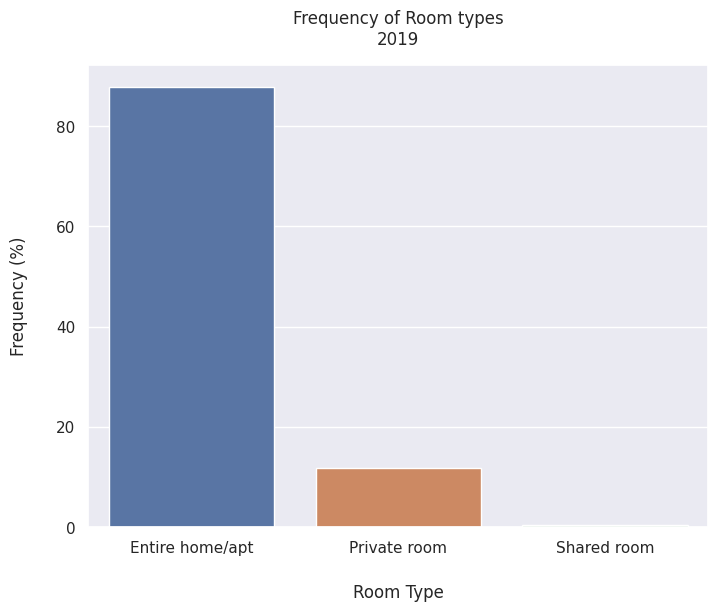

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ax = sns.countplot(
    data=data_19.drop_duplicates(subset=['id']),
    x='room_type',
    hue='room_type',
    legend='',
    stat='percent',
    palette=sns.color_palette()[:3],
)

ax.set_title('Frequency of Room types\n2019', pad=15)
ax.set_xlabel('Room Type', labelpad=20)
ax.set_ylabel('Frequency (%)', labelpad=20)

plt.show()

### 2023

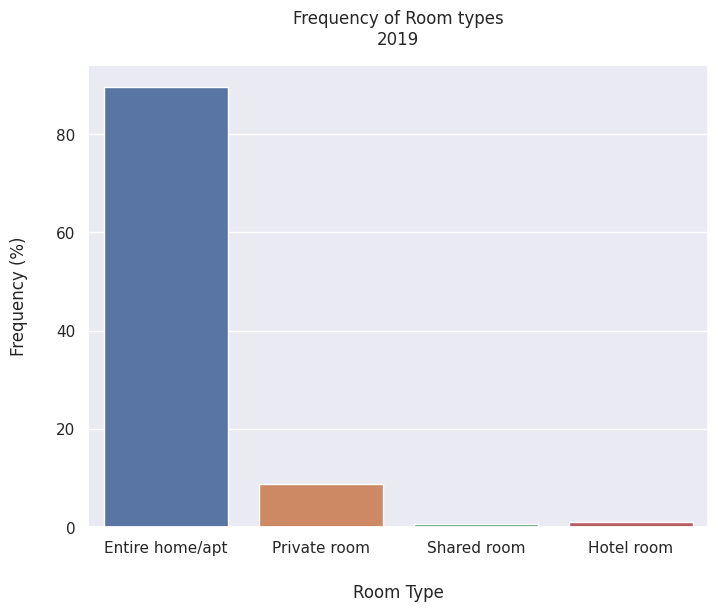

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ax = sns.countplot(
    data=data_23.drop_duplicates(subset=['id']),
    x='room_type',
    hue='room_type',
    legend='',
    stat='percent',
    palette=sns.color_palette()[:4],
)

ax.set_title('Frequency of Room types\n2019', pad=15)
ax.set_xlabel('Room Type', labelpad=20)
ax.set_ylabel('Frequency (%)', labelpad=20)

plt.show()

## 1.2 Monthly Price Variation

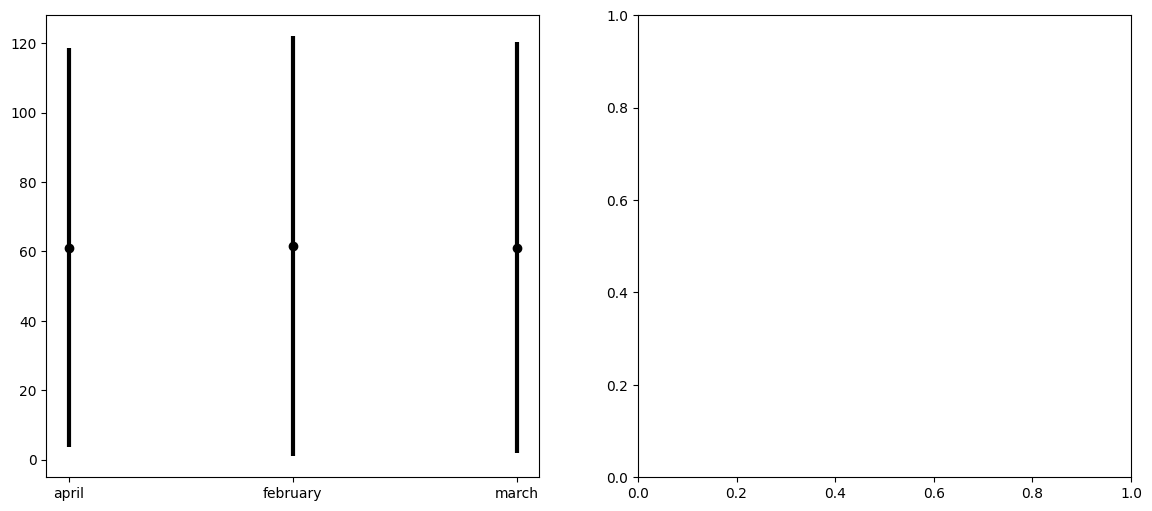

In [ ]:
# AVERAGE PRICE

prices_19_mean = data_19.groupby('month')['price'].mean()
prices_19_min = data_19.groupby('month')['price'].min()
prices_19_max = data_19.groupby('month')['price'].max()
prices_19_std = data_19.groupby('month')['price'].std()
months_19 = prices_19_mean.index.values.tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.errorbar(months_19, prices_19_mean, prices_19_std, fmt='ok', lw=3)

plt.show()

## 1.3 Neighbourhoods Ranked by Review Counts

Compare the ten highest aggregated review counts in each snapshot year. Counts sum listing-level totals across monthly snapshots, so they can include repeated contributions from the same listing.

### 2019 - 2023

In [ ]:
data_19.groupby('neighbourhood')['number_of_reviews'].sum().sort_values(ascending=False)[0:10]

neighbourhood
ΕΜΠΟΡΙΚΟ ΤΡΙΓΩΝΟ-ΠΛΑΚΑ              167170
ΚΟΥΚΑΚΙ-ΜΑΚΡΥΓΙΑΝΝΗ                  90687
ΝΕΟΣ ΚΟΣΜΟΣ                          69102
ΜΟΥΣΕΙΟ-ΕΞΑΡΧΕΙΑ-ΝΕΑΠΟΛΗ             59256
ΑΓΙΟΣ ΚΩΝΣΤΑΝΤΙΝΟΣ-ΠΛΑΤΕΙΑ ΒΑΘΗΣ     49406
ΑΚΡΟΠΟΛΗ                             39325
ΘΗΣΕΙΟ                               35587
ΠΑΓΚΡΑΤΙ                             32338
ΠΛΑΤΕΙΑ ΑΤΤΙΚΗΣ                      30500
ΑΜΠΕΛΟΚΗΠΟΙ                          26710
Name: number_of_reviews, dtype: int64

In [ ]:
data_23.groupby('neighbourhood')['number_of_reviews'].sum().sort_values(ascending=False)[0:10]

neighbourhood
ΕΜΠΟΡΙΚΟ ΤΡΙΓΩΝΟ-ΠΛΑΚΑ              433484
ΚΟΥΚΑΚΙ-ΜΑΚΡΥΓΙΑΝΝΗ                 207147
ΝΕΟΣ ΚΟΣΜΟΣ                         129430
ΜΟΥΣΕΙΟ-ΕΞΑΡΧΕΙΑ-ΝΕΑΠΟΛΗ            103904
ΑΓΙΟΣ ΚΩΝΣΤΑΝΤΙΝΟΣ-ΠΛΑΤΕΙΑ ΒΑΘΗΣ    102836
ΑΚΡΟΠΟΛΗ                             77875
ΘΗΣΕΙΟ                               77324
ΚΕΡΑΜΕΙΚΟΣ                           56131
ΠΑΓΚΡΑΤΙ                             52840
ΠΛΑΤΕΙΑ ΑΤΤΙΚΗΣ                      49531
Name: number_of_reviews, dtype: int64

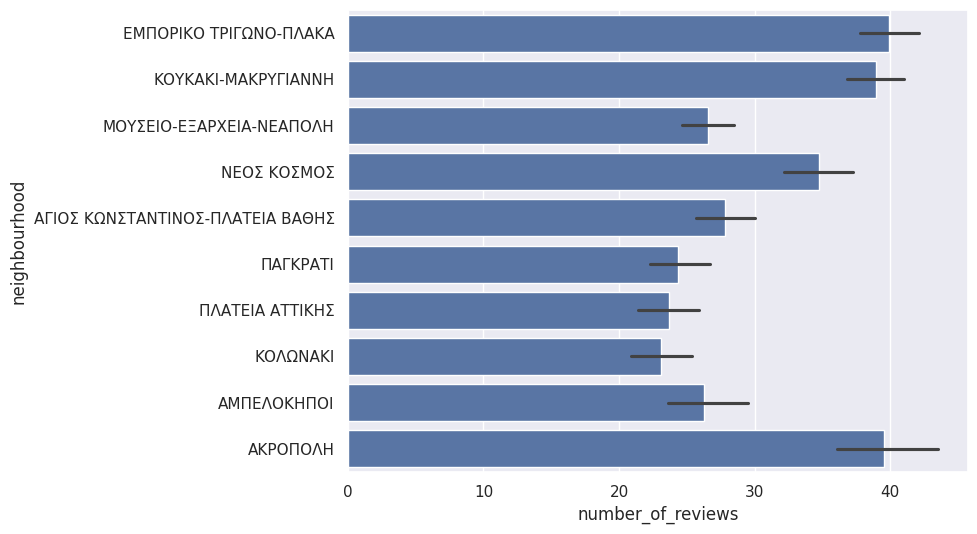

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

ax = sns.barplot(
    data=data_19,
    x='number_of_reviews',
    y='neighbourhood',
    legend='',
    order=data_19['neighbourhood'].value_counts().iloc[:10].index
)

# ax.set_title('Frequency of Room types\n2019', pad=15)
# ax.set_xlabel('Room Type', labelpad=20)
# ax.set_ylabel('Frequency (%)', labelpad=20)

plt.show()

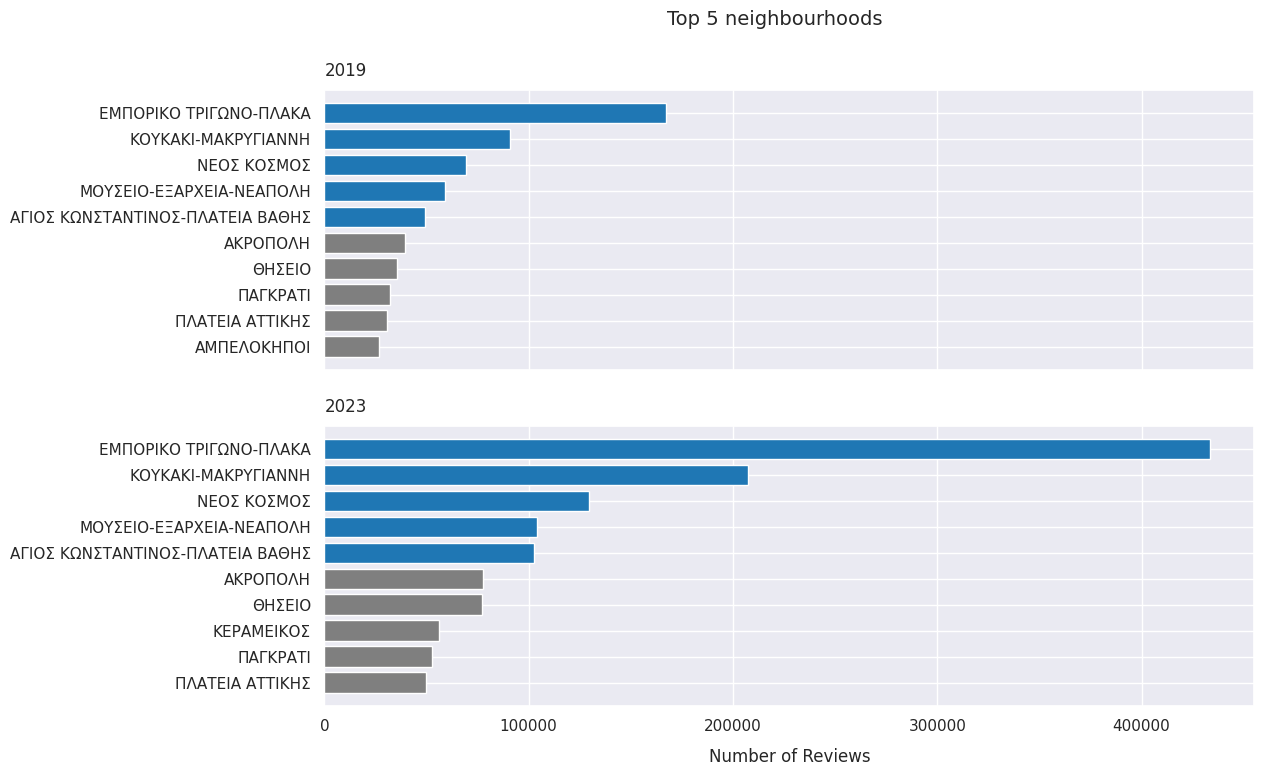

In [ ]:
neigh_reviews_19 = data_19.groupby('neighbourhood')['number_of_reviews'].sum().sort_values(ascending=False)[0:10]
neigh_reviews_23 = data_23.groupby('neighbourhood')['number_of_reviews'].sum().sort_values(ascending=False)[0:10]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
fig.suptitle('Top 5 neighbourhoods', fontsize=14)

# bar_labels = ['red', 'blue', 'orange']
# bar_colors = ['tab:green', 'tab:blue', 'tab:red']

top_neigh_19 = neigh_reviews_19.index.values.tolist()
top_neigh_23 = neigh_reviews_23.index.values.tolist()


y_pos_19 = np.arange(len(top_neigh_19))
y_pos_23 = np.arange(len(top_neigh_23))

colors = ['tab:blue', 'tab:blue', 'tab:blue', 'tab:blue', 'tab:blue',
          'tab:grey', 'tab:grey', 'tab:grey', 'tab:grey', 'tab:grey', ]

ax1.barh(y_pos_19, neigh_reviews_19.values, align='center', color=colors)
ax1.set_yticks(y_pos_19, labels=top_neigh_19)
ax1.invert_yaxis()

# ax1.set_xlabel('Number of Rooms', labelpad=10)
ax1.set_title('2019', pad=10, loc='left')

ax2.barh(y_pos_23, neigh_reviews_23.values, align='center', color=colors)
ax2.set_yticks(y_pos_23, labels=top_neigh_23)
ax2.invert_yaxis()

ax2.set_xlabel('Number of Reviews', labelpad=10)
ax2.set_title('2023', pad=10, loc='left')

plt.show()

## 1.4 Neighbourhoods with the Most Unique Listings

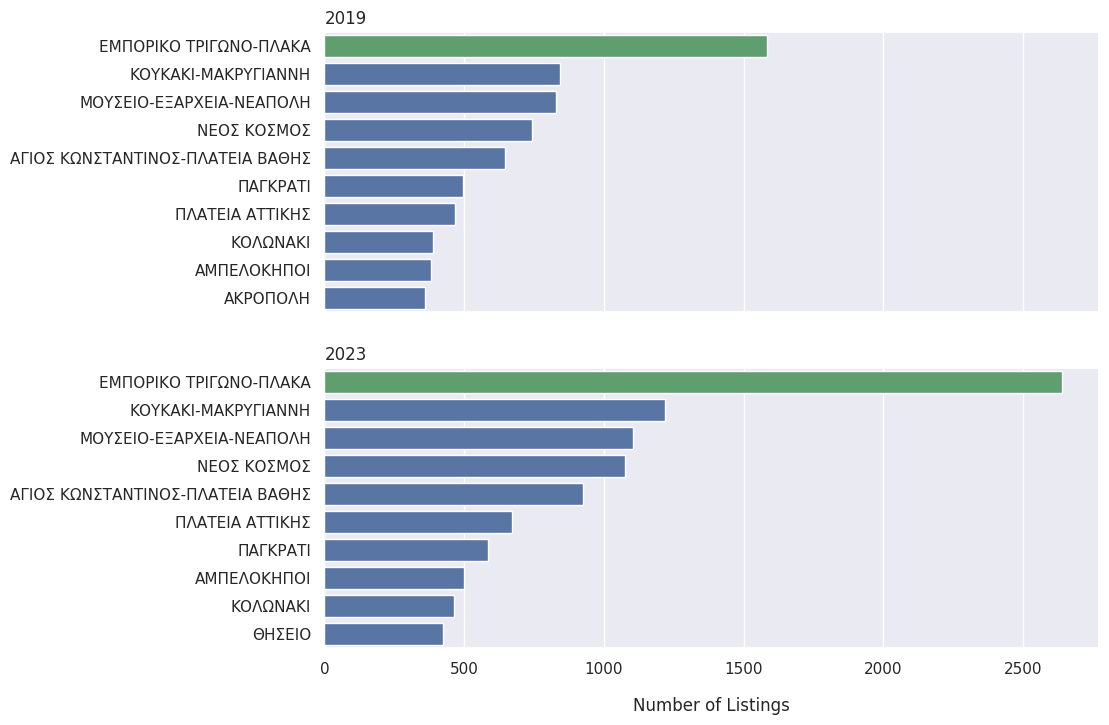

In [ ]:
neigh_listings_19 = data_19.drop_duplicates(subset=['id']).groupby('neighbourhood')['id'].count().sort_values(ascending=False)[:10]
neigh_listings_23 = data_23.drop_duplicates(subset=['id']).groupby('neighbourhood')['id'].count().sort_values(ascending=False)[:10]

neighbourhoods_19 = neigh_listings_19.index.values.tolist()[:10]
neighbourhoods_23 = neigh_listings_23.index.values.tolist()[:10]

colors = ['b' if (x < max(neigh_listings_19)) else 'g' for x in neigh_listings_19 ]


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.barplot(ax=ax1, x=neigh_listings_19, y=neighbourhoods_19, hue=neighbourhoods_19, legend=False, palette=colors, orient='h')
ax1.set_title('2019', loc='left')

sns.barplot(ax=ax2, x=neigh_listings_23, y=neighbourhoods_23, hue=neighbourhoods_23, legend=False, palette=colors, orient='h')
ax2.set_title('2023', loc='left')
ax2.set_xlabel('Number of Listings', labelpad=15)

plt.show()


## 1.5 Listings by Neighbourhood and Month

### 2019:

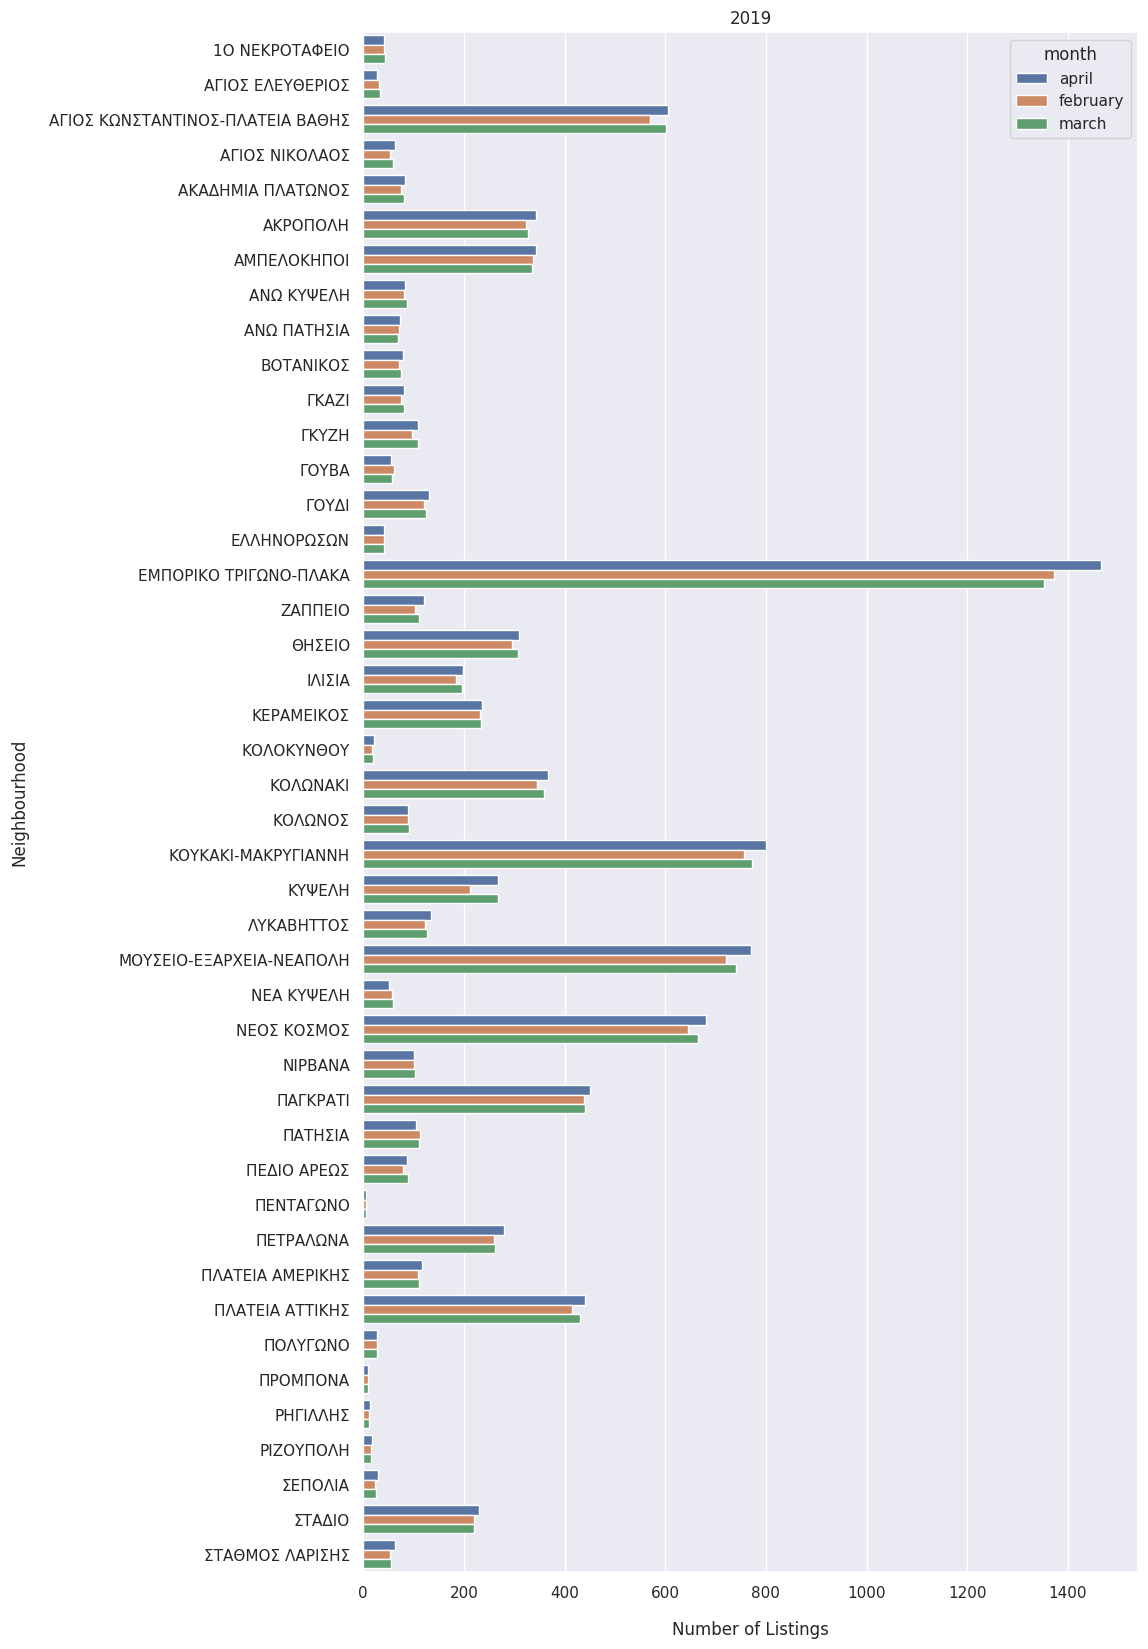

In [ ]:
fig, ax = plt.subplots(figsize=(10, 20))
sns.set_theme()
sns.set_palette(sns.color_palette())
sns.set_color_codes("pastel")

sns.barplot(
    ax=ax,
    x='id',
    y='neighbourhood',
    hue='month',
    data=data_19.groupby(['neighbourhood', 'month']).count(),
    legend=True,
    orient='h'
)
ax.set_title('2019')
ax.set_ylabel('Neighbourhood', labelpad=15)
ax.set_xlabel('Number of Listings', labelpad=15)

plt.show()

### 2023:

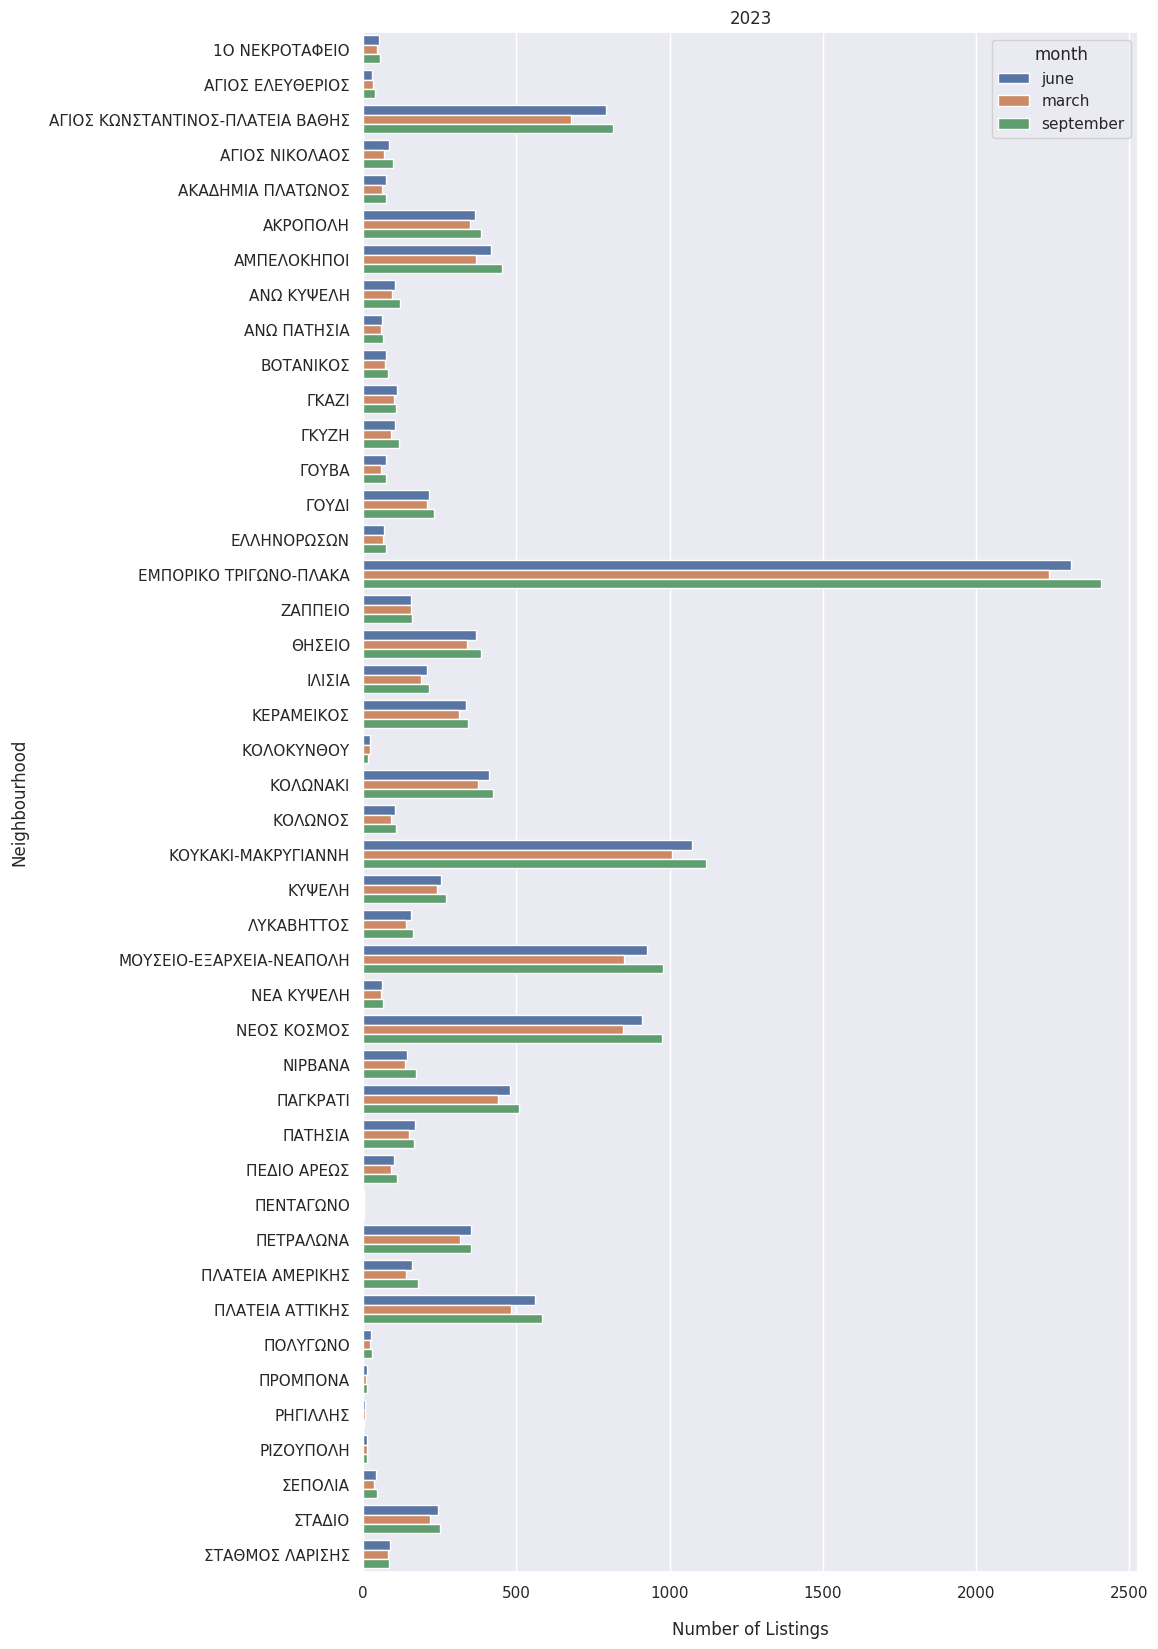

In [ ]:
fig, ax = plt.subplots(figsize=(10, 20))
sns.set_theme()
sns.set_palette(sns.color_palette())
sns.set_color_codes("pastel")

sns.barplot(
    ax=ax,
    x='id',
    y='neighbourhood',
    hue='month',
    data=data_23.groupby(['neighbourhood', 'month']).count(),
    legend=True,
    orient='h'
)
ax.set_title('2023')
ax.set_ylabel('Neighbourhood', labelpad=15)
ax.set_xlabel('Number of Listings', labelpad=15)

plt.show()

## 1.6 Distribution of Listings Across Neighbourhoods

### 2019:

<ipython-input-31-d58fabdd9509>:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  my_plot.set_xticklabels(my_plot.get_xticklabels(), rotation=90)


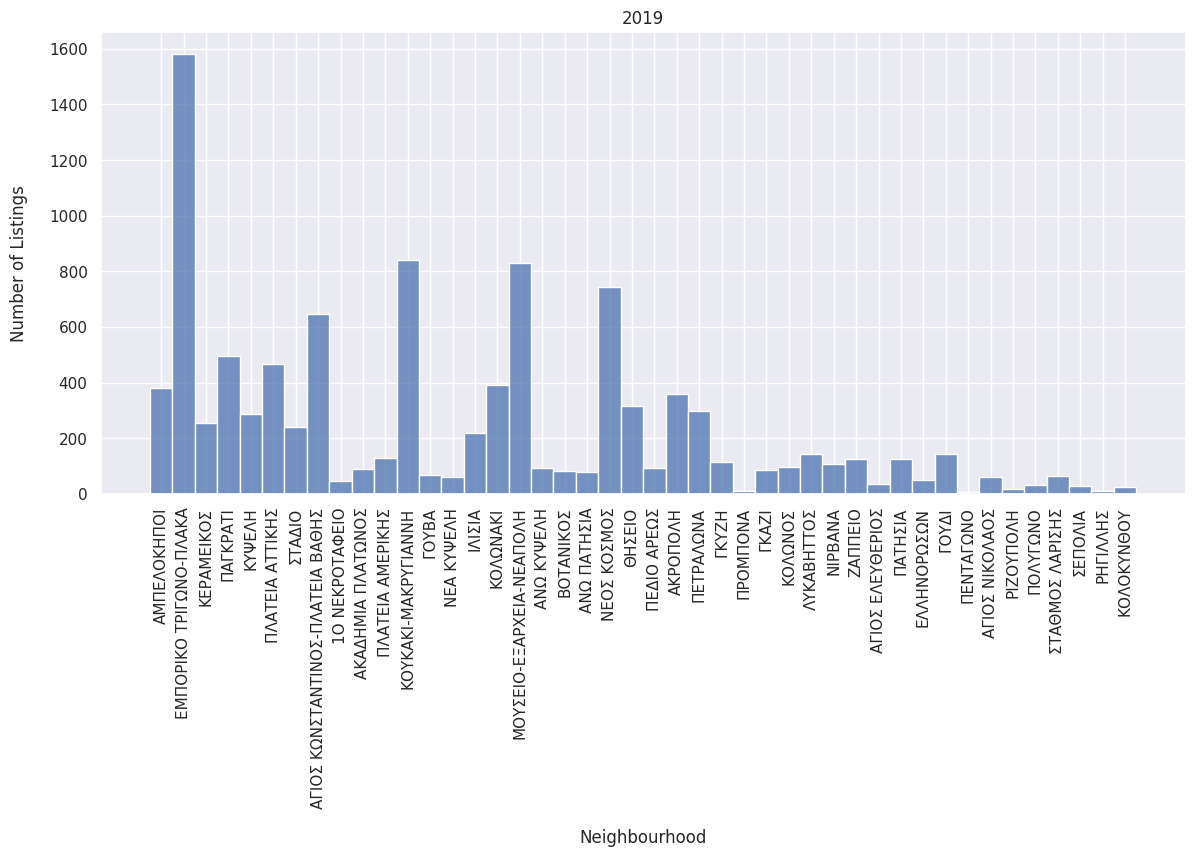

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.set_theme()
sns.set_palette(sns.color_palette())
sns.set_color_codes("pastel")

my_plot = sns.histplot(
    ax=ax,
    x='neighbourhood',
    data=data_19.drop_duplicates(subset=['id']),
    legend=False
)

my_plot.set_xticklabels(my_plot.get_xticklabels(), rotation=90)

ax.set_title('2019')
ax.set_ylabel('Number of Listings', labelpad=15)
ax.set_xlabel('Neighbourhood', labelpad=15)

plt.show()

### 2023:

<ipython-input-30-fb0ca354dbca>:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  my_plot.set_xticklabels(my_plot.get_xticklabels(), rotation=90)


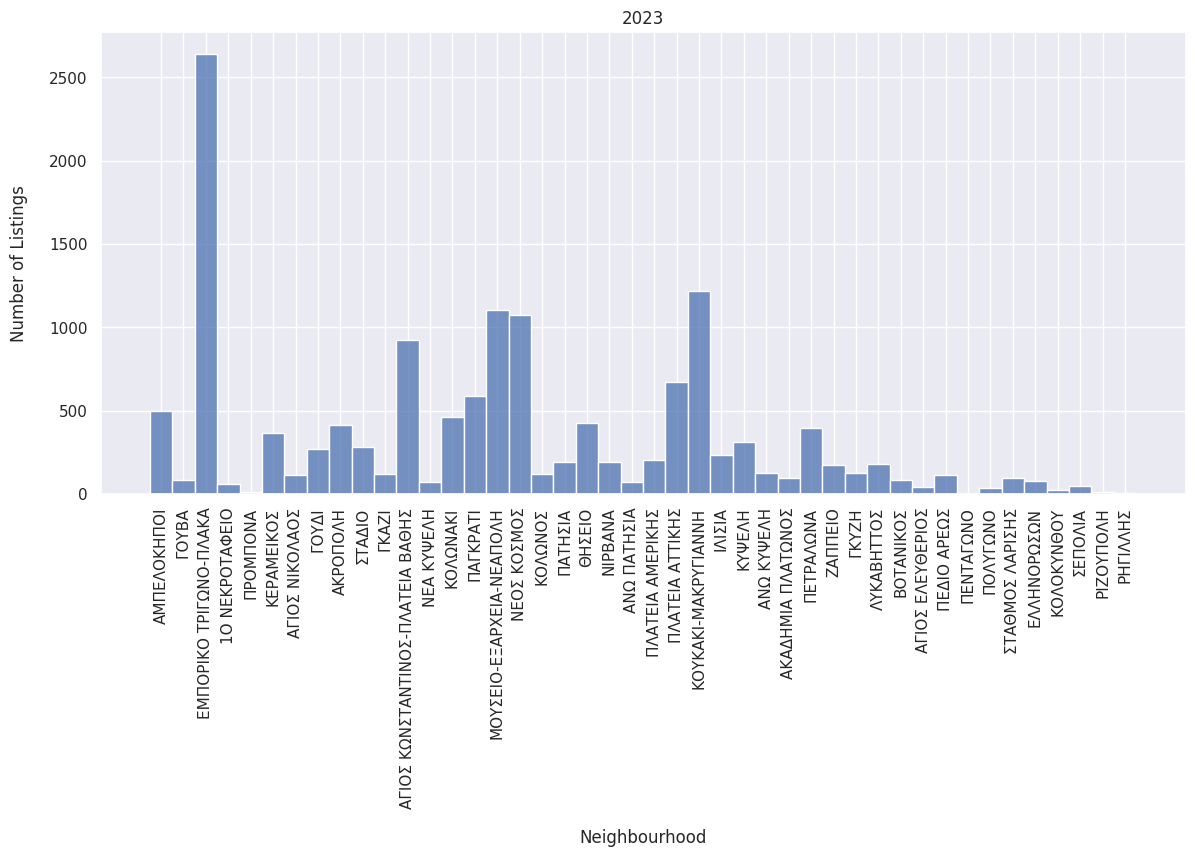

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.set_theme()
sns.set_palette(sns.color_palette())
sns.set_color_codes("pastel")

my_plot = sns.histplot(
    ax=ax,
    x='neighbourhood',
    data=data_23.drop_duplicates(subset=['id']),
    legend=False
)

my_plot.set_xticklabels(my_plot.get_xticklabels(), rotation=90)

ax.set_title('2023')
ax.set_ylabel('Number of Listings', labelpad=15)
ax.set_xlabel('Neighbourhood', labelpad=15)

plt.show()

## 1.7 Room Types by Neighbourhood

### 2019:

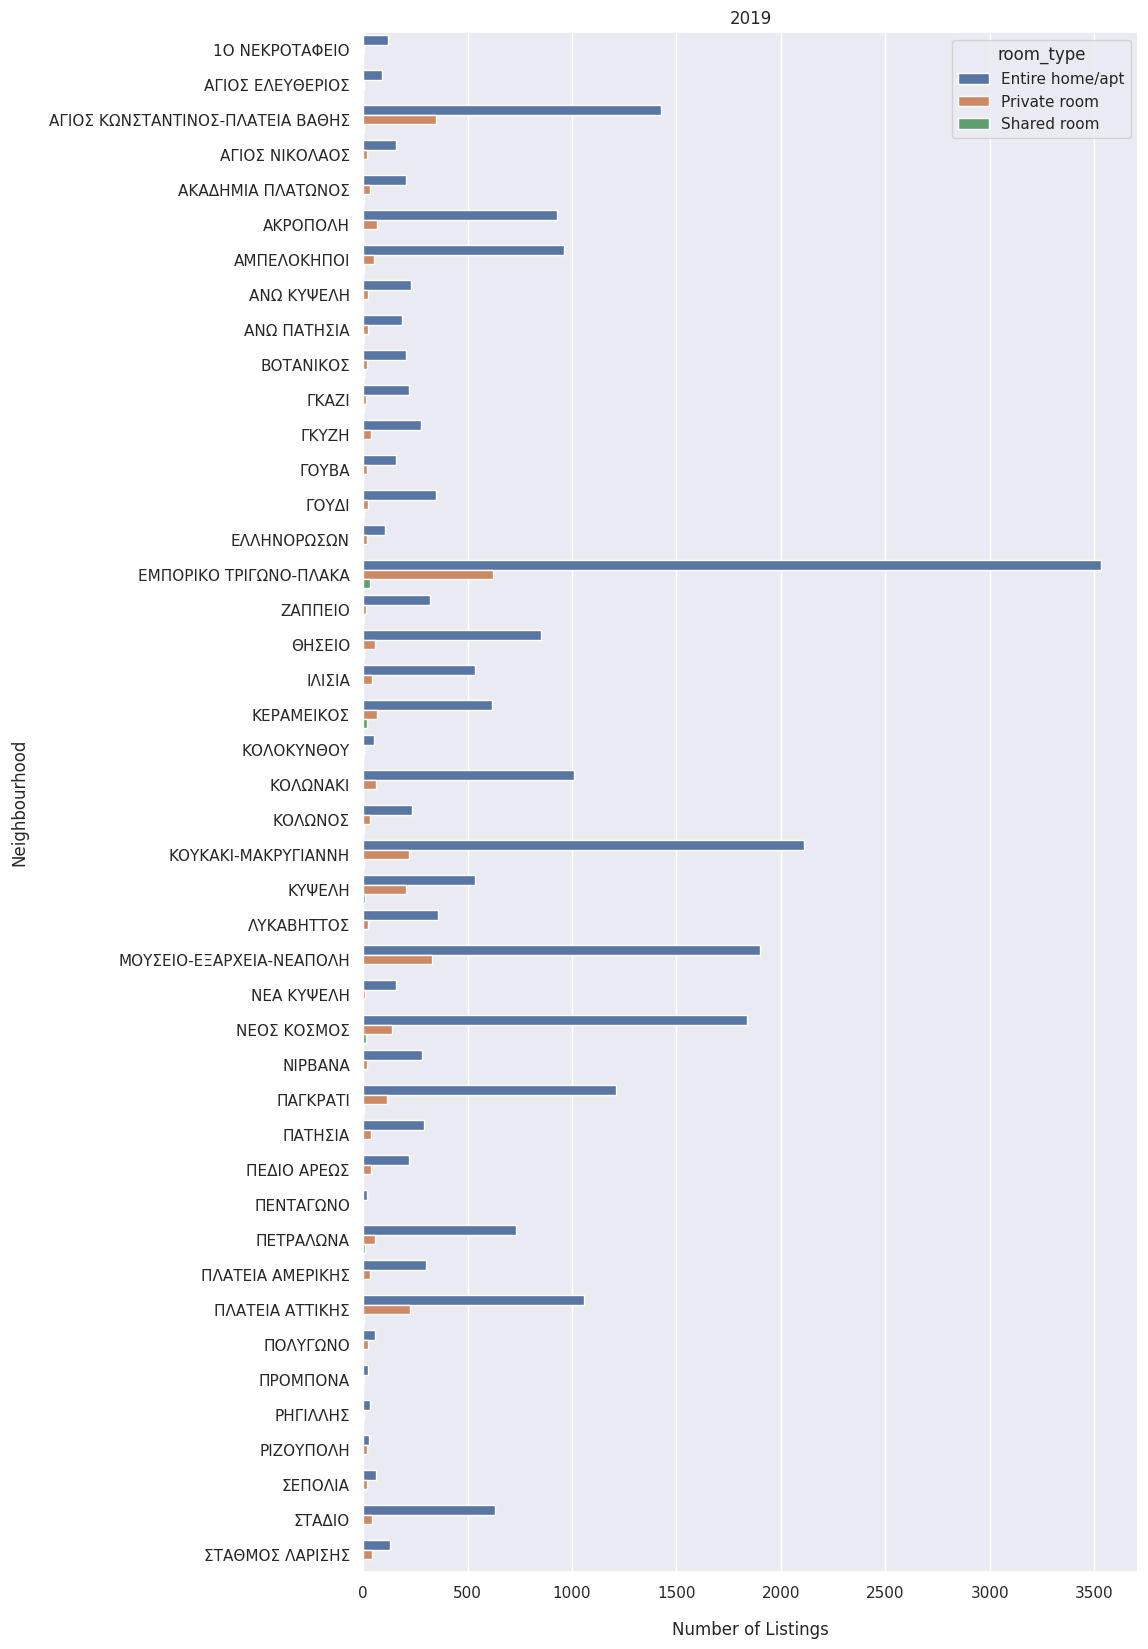

In [ ]:
fig, ax = plt.subplots(figsize=(10, 20))
sns.set_theme()
sns.set_palette(sns.color_palette())
sns.set_color_codes("pastel")

sns.barplot(
    ax=ax,
    x='id',
    y='neighbourhood',
    hue='room_type',
    data=data_19.groupby(['neighbourhood', 'room_type']).count(),
    legend=True,
    orient='h'
)
ax.set_title('2019')
ax.set_ylabel('Neighbourhood', labelpad=15)
ax.set_xlabel('Number of Listings', labelpad=15)

plt.show()

### 2023:

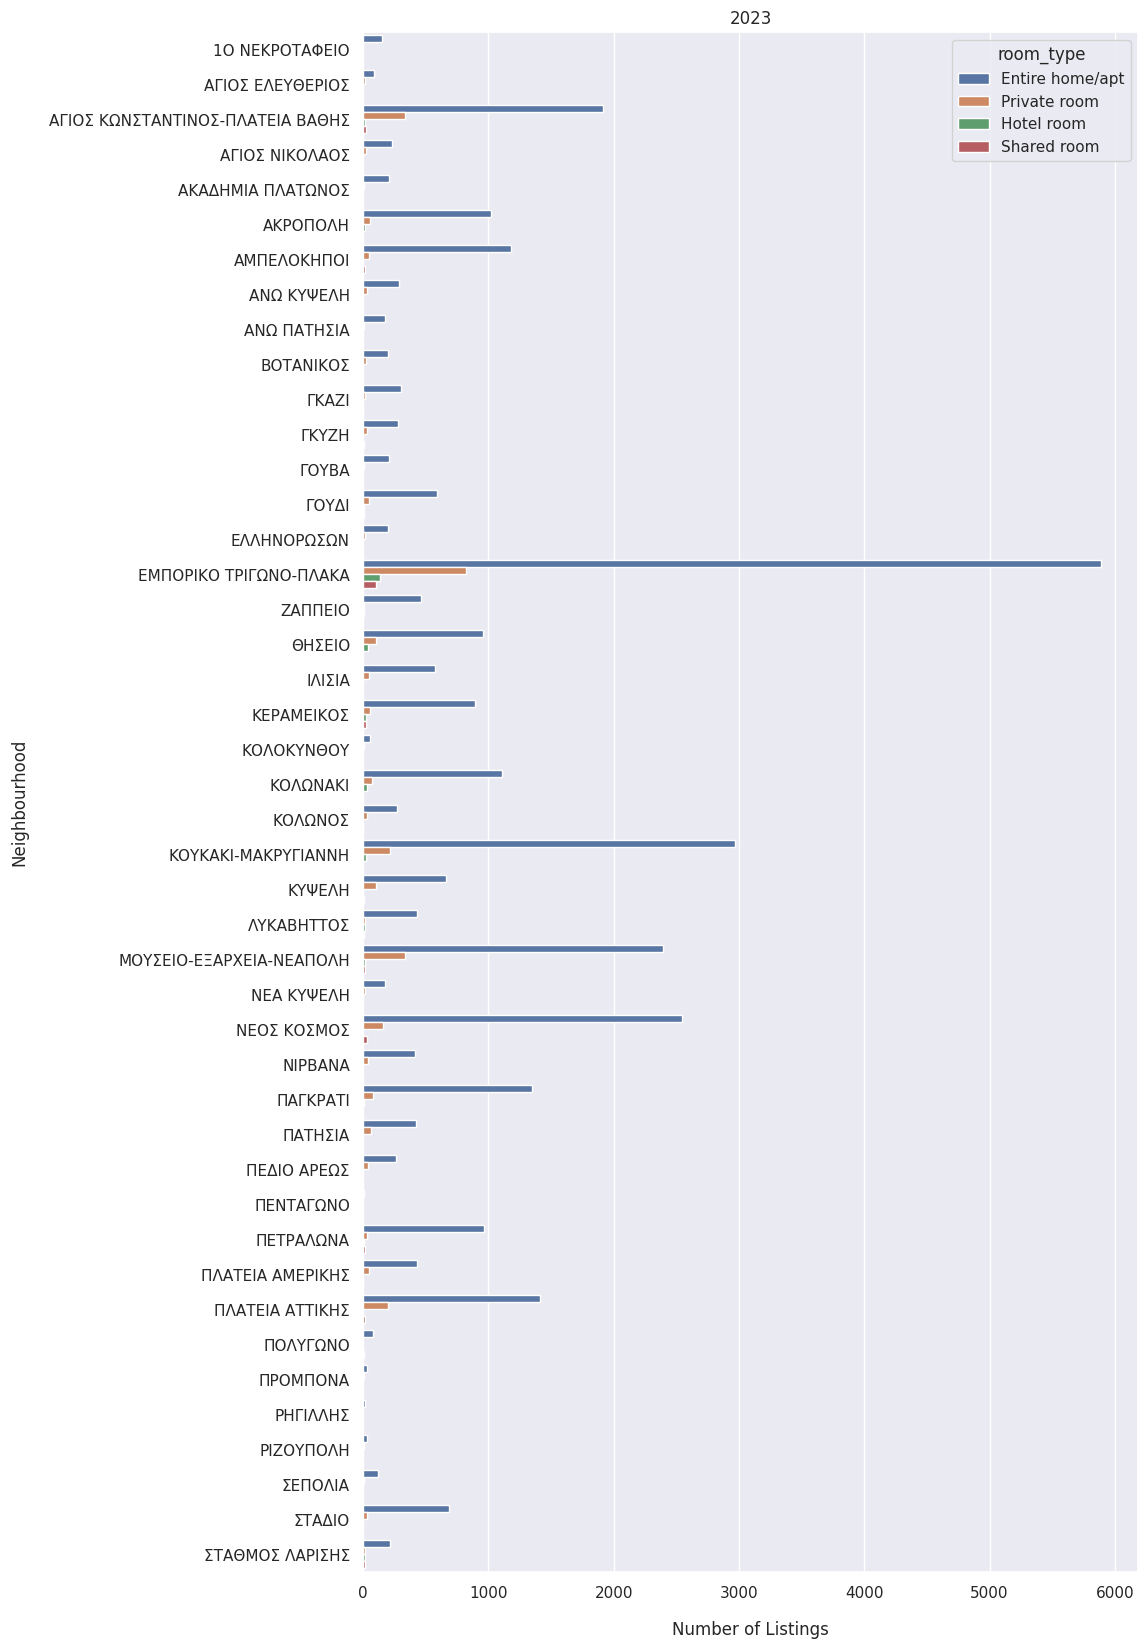

In [ ]:
fig, ax = plt.subplots(figsize=(10, 20))
sns.set_theme()
sns.set_palette(sns.color_palette())
sns.set_color_codes("pastel")

sns.barplot(
    ax=ax,
    x='id',
    y='neighbourhood',
    hue='room_type',
    data=data_23.groupby(['neighbourhood', 'room_type']).count(),
    legend=True,
    orient='h'
)
ax.set_title('2023')
ax.set_ylabel('Neighbourhood', labelpad=15)
ax.set_xlabel('Number of Listings', labelpad=15)

plt.show()

## 1.8 Price Distributions by Room Type

### 2019:

Text(0.5, 0, 'Price')

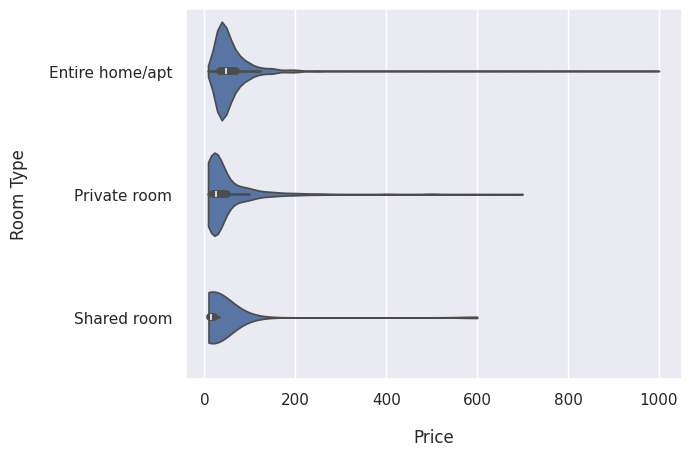

In [ ]:
ax = sns.violinplot(
    data=data_19.drop_duplicates(subset=['id']),
    x="price",
    y="room_type",
    cut=0,
    split=False,
    density_norm = "area"
)

ax.set_ylabel("Room Type", labelpad=15)
ax.set_xlabel("Price", labelpad=15)

### 2023:

Text(0.5, 0, 'Price')

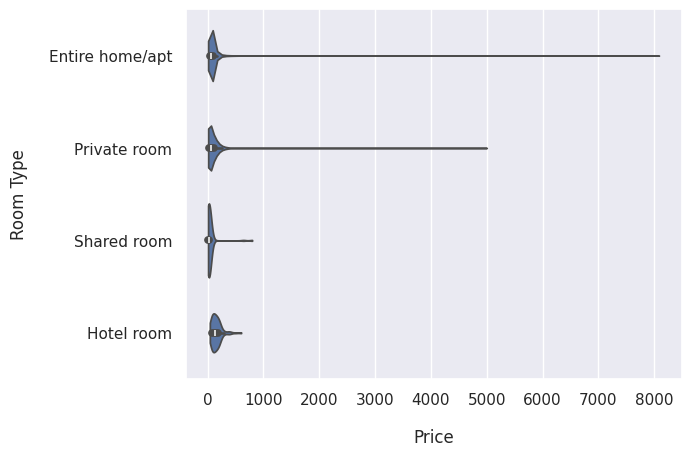

In [ ]:
ax = sns.violinplot(
    data=data_23.drop_duplicates(subset=['id']),
    x="price",
    y="room_type",
    cut=0,
    split=False,
    density_norm = "area"
)

ax.set_ylabel("Room Type", labelpad=15)
ax.set_xlabel("Price", labelpad=15)

## 1.9 Interactive Listing Map

Map a sample of 300 listings from April 2019 using Folium marker clusters. Each popup shows the room type, listing name and price.

In [ ]:
import folium
import folium.map
from folium import plugins

map_data_19 = data_19[data_19['month'] == 'april']
map_data_19 = map_data_19[['id', 'name', 'latitude', 'longitude', 'room_type', 'price']].sample(300)

fig = folium.Figure(width = '1024', height ='576')

map = folium.Map(
    location=[map_data_19['latitude'].mean(), map_data_19['longitude'].mean()],
    zoom_start=14,
    control_scale=True,
    tiles='openstreetmap'
).add_to(fig)

rooms = plugins.MarkerCluster().add_to(map)

for idx, row in map_data_19.iterrows():
    folium.Marker(
        location=[row['latitude'], row['longitude']],
        icon=None,
        popup=f"{row['room_type']}\n ----- {row['name']}\n ----- ({row['price']}$)",
    ).add_to(rooms)

map.add_child(rooms)
map

## 1.10 Word Clouds

Visualise frequently occurring words in neighbourhood names, transit information and listing descriptions.

### 2019

#### Column: `neighbourhood`

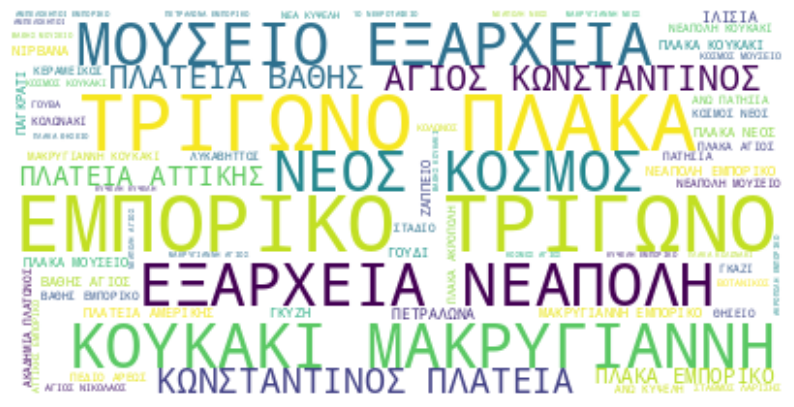

In [ ]:
words = " ".join(data_19['neighbourhood'])

wc = WordCloud(max_font_size=50, max_words=100, background_color="white").generate(words)

plt.figure(figsize=(10, 8))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")

plt.show()

#### Column: `transit`

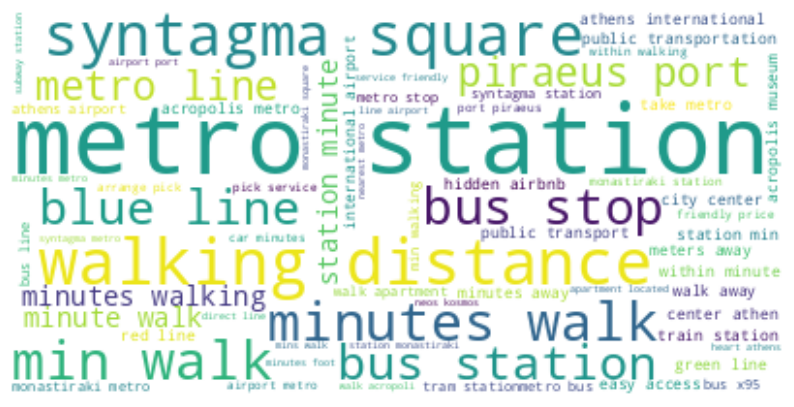

In [ ]:
words = " ".join(data_19[(data_19['clean_transit'].notnull())]['clean_transit'])

wc = WordCloud(max_font_size=50, max_words=100, background_color="white").generate(words)

plt.figure(figsize=(10, 8))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")

plt.show()

#### Column: `description`

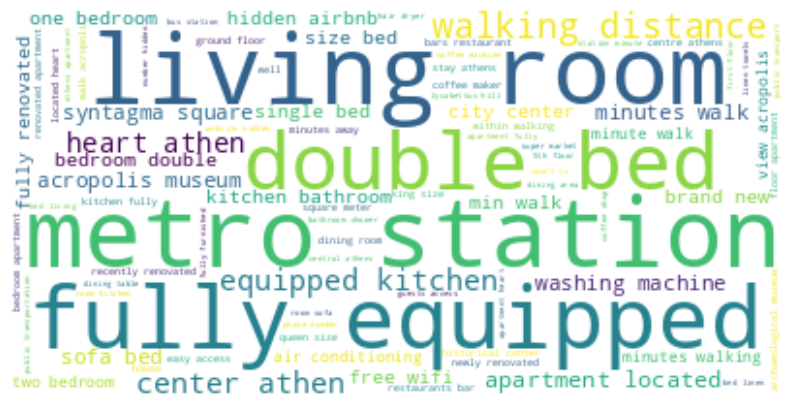

In [ ]:
words = " ".join(data_19[(data_19['clean_description'].notnull())]['clean_description'])

wc = WordCloud(max_font_size=50, max_words=100, background_color="white").generate(words)

plt.figure(figsize=(10, 8))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")

plt.show()

### 2023

#### Column: `neighbourhood`

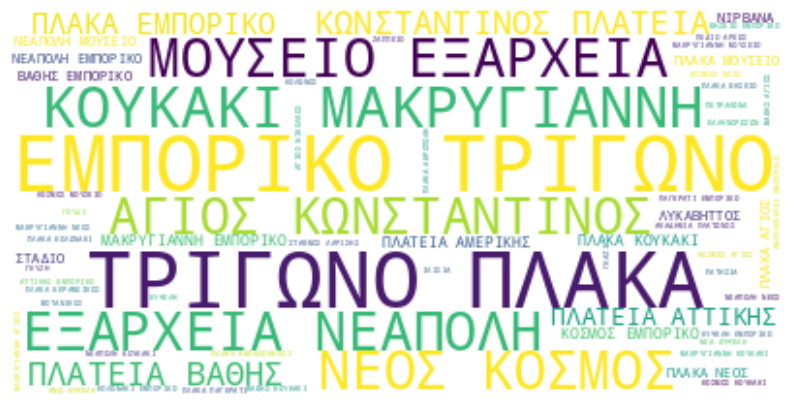

In [ ]:
words = " ".join(data_23['neighbourhood'])

wc = WordCloud(max_font_size=50, max_words=100, background_color="white").generate(words)

plt.figure(figsize=(10, 8))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")

plt.show()

#### Column: `description`

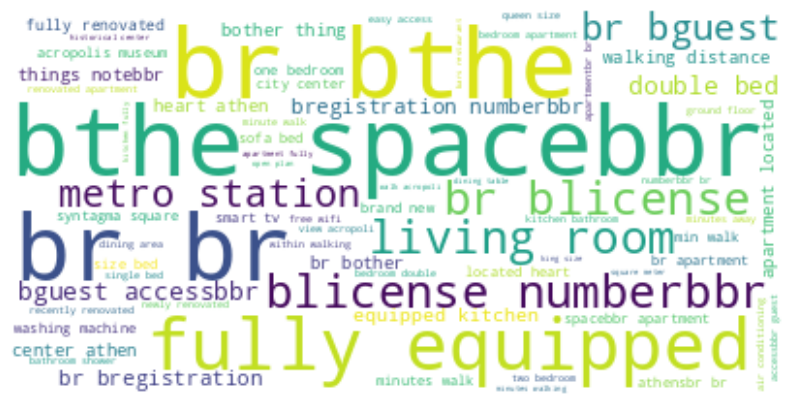

In [ ]:
words = " ".join(data_23[(data_23['clean_description'].notnull())]['clean_description'])

wc = WordCloud(max_font_size=50, max_words=100, background_color="white").generate(words)

plt.figure(figsize=(10, 8))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")

plt.show()

# 2. Content-Based Listing Recommendations

Represent listing names and descriptions as TF-IDF vectors and rank properties by cosine similarity. Similarity scores describe textual overlap; recommendation quality has not been measured against user preferences.

In [ ]:
# Create new concatenated column.
data_19['name_description'] = data_19['clean_name'] + data_19['clean_description']
data_19['name_description'].fillna("", inplace=True)

# Create sample with no duplicates based on id and non-empty 'name_description'.
sample = data_19[data_19[['name_description']].notnull().all(1)].drop_duplicates(subset='id')
sample = sample.sample(500)[['id', 'name', 'description', 'name_description']]
sample.reset_index(inplace=True, drop=True)

## 2.1 TF-IDF Features

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf_idf_vect = TfidfVectorizer(max_df=1.0, min_df=20, max_features=None, stop_words='english')
tf_idf = tf_idf_vect.fit_transform(sample['name_description'])

sample['tf_idf'] = tf_idf.toarray().tolist()        # Add to sample df.

print('\nTF-IDF Shape:')
print(tf_idf.shape)
print('\nWord Vocabulary:')
print(*tf_idf_vect.vocabulary_.items(), sep='\n')


TF-IDF Shape:
(500, 311)

Word Vocabulary:
('modern', 183)
('city', 50)
('fully', 112)
('equipped', 89)
('recently', 227)
('decorated', 69)
('needs', 191)
('tourist', 285)
('bedroom', 34)
('flat', 103)
('located', 161)
('center', 47)
('athens', 23)
('apartment', 14)
('sqm', 261)
('5th', 1)
('floor', 105)
('building', 42)
('entrance', 87)
('hall', 125)
('living', 159)
('room', 236)
('screen', 240)
('tv', 294)
('dining', 74)
('table', 279)
('sofa', 257)
('kitchen', 146)
('renovated', 231)
('bathroom', 31)
('comfortable', 56)
('double', 78)
('bed', 33)
('terrace', 281)
('enjoy', 85)
('coffee', 54)
('sunny', 274)
('day', 68)
('meters', 177)
('away', 26)
('syntagma', 278)
('metro', 178)
('station', 263)
('large', 150)
('queen', 223)
('size', 253)
('extra', 95)
('linens', 156)
('towels', 286)
('big', 38)
('great', 117)
('couch', 65)
('sleep', 254)
('light', 152)
('amazing', 11)
('open', 203)
('space', 259)
('night', 197)
('view', 298)
('flatscreen', 104)
('maker', 174)
('fridge', 110)
('cos

## 2.2 Cosine Similarity

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

cs_matrix = cosine_similarity(tf_idf).tolist()

similars = []
for cs_list in cs_matrix:
    new_list = list(enumerate(cs_list))
    new_list.sort(key=lambda x: x[1], reverse=True)
    similars.append(new_list[:100])

sample['similars'] = similars       # Add to sample df.

In [ ]:
print(cosine_similarity(tf_idf))

[[1.         0.11881084 0.16992211 ... 0.         0.10700118 0.24429025]
 [0.11881084 1.         0.22221775 ... 0.         0.27543223 0.07676419]
 [0.16992211 0.22221775 1.         ... 0.         0.35999307 0.19799167]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.10700118 0.27543223 0.35999307 ... 0.         1.         0.18064426]
 [0.24429025 0.07676419 0.19799167 ... 0.         0.18064426 1.        ]]


## 2.3 Recommendation Example

In [ ]:
import textwrap
wrapper = textwrap.TextWrapper(width=120)

def recommend(item_id: int, num: int, data: pd.DataFrame) -> None:
    if not item_id:
        print("Error: You need to provide an item_id!")
    if not num:
        print("Error: You need to provide a number for recommendations!")

    item = data[data['id'] == item_id]
    recs = item.iloc[0]['similars']
    recs = recs[1:num + 1]

    print(f"\nRecommending {num} listings similar to: #{item.iloc[0]['id']}: {item.iloc[0]['name']}")
    print("-" * 120)
    for i, rec in enumerate(recs):
        idx = rec[0]
        score = rec[1]
        print(f"{i+1}. Recommended: #{data['id'][idx]}")
        print(f"Name: {data['name'][idx]}")
        print(f"Description: ")
        lines = wrapper.wrap(data.iloc[idx]['description'])
        print(*lines, sep='\n')
        print(f" [score: {score}]")
        print("\n")

recommend(11335951, 5, data=sample)



Recommending 5 listings similar to: #11335951: The Erasmus Flat
------------------------------------------------------------------------------------------------------------------------
1. Recommended: #4006764
Name: Small Patio flat in Athens Greece
Description: 
Flat 35 square meters. Fully furnished. With balcony and a view to the Parthenon. One Isolated flat per floor with
exclusive elevator use.  It is close to national road and close to the centre of Athens. Available all the time to help.
 [score: 0.43559355300267955]


2. Recommended: #18579388
Name: Charming flat next to Acropolis!
Description: 
A newly revamped one-bedroom apartment at the foot of the Acropolis! Next to Sygrou Station. Everything in the flat is
brand new from furniture to appliances. Bedlinen and towels are sent to the  laundry, ironed and pressed to a crisp
finish. The flat is tastefully  decorated and located in one of the trendiest neighbourhoods in Athens and within
walking distance to all the important p

## 2.4 Bigram Collocations

Extract frequently associated word pairs using pointwise mutual information. This is separate from the unigram TF-IDF representation used by the recommender.

In [ ]:
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures

words = word_tokenize(" ".join(data_19['name_description']))

bigram_measures = BigramAssocMeasures()
finder = BigramCollocationFinder.from_words(words)
finder.apply_freq_filter(3)
finder.nbest(bigram_measures.pmi, 10)

[('100sqdream', 'apartacropolis'),
 ('13ppl', 'capacitylisting'),
 ('140sqmt', '6pers'),
 ('15minutes5km', 'exarhiaomonia'),
 ('16101525', '34'),
 ('1860s', 'homefeaturing'),
 ('1meeting', 'roompcsfaxlandline'),
 ('1p', 'resp'),
 ('1pc', 'extra10day'),
 ('1pm', '11pmother')]